# Combinatorial Optimization Problems: Overview

In [1]:
import torch

from core.problems.tsp.solution import TSPSolution

%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt

from core.problems.archive.op import OPConfig, get_op_generator, visualize_op_instance
from core.problems.cvrp import CVRPConfig, CVRPInstance, CVRPSolution, TensorDictCVRPSampler
from core.problems.tsp import TensorTSPSampler, TSPConfig, TSPInstance

## Traveling Salesman Problem

tensor([[0.2673, 0.8725],
        [0.3353, 0.4030],
        [0.7871, 0.4576],
        [0.0719, 0.9715],
        [0.7147, 0.4275],
        [0.0846, 0.4904],
        [0.1662, 0.1538],
        [0.3638, 0.5145],
        [0.7122, 0.8787],
        [0.8431, 0.9879],
        [0.5595, 0.4359],
        [0.1276, 0.2768],
        [0.7556, 0.4555],
        [0.1029, 0.7771],
        [0.9581, 0.6336],
        [0.2488, 0.8578],
        [0.8870, 0.0478],
        [0.1390, 0.1038],
        [0.4049, 0.4521],
        [0.1290, 0.4728]])


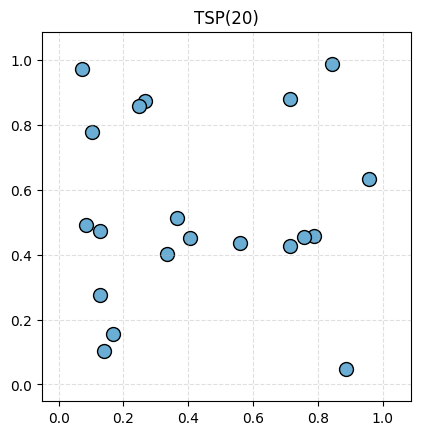

In [2]:
tsp_config = TSPConfig(num_locations=20)
tsp_sampler = TensorTSPSampler(tsp_config)
t = tsp_sampler(2)
print(t[0])

instance = TSPInstance.from_tensor(t[0])
instance.visualize()
plt.show()

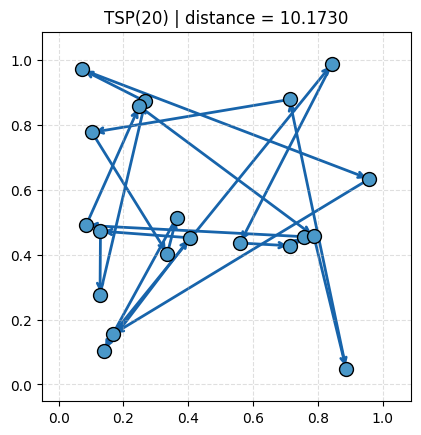

In [22]:
random_tour = torch.randperm(tsp_config.num_locations)
example_tsp_solution = TSPSolution(instance, tour=random_tour)
example_tsp_solution.visualize()

## Capacitated Vehicle Problem

TensorDict(
    fields={
        capacity: Tensor(shape=torch.Size([2, 1]), device=cpu, dtype=torch.float32, is_shared=False),
        demand: Tensor(shape=torch.Size([2, 21]), device=cpu, dtype=torch.float32, is_shared=False),
        nodes: Tensor(shape=torch.Size([2, 21, 2]), device=cpu, dtype=torch.float32, is_shared=False)},
    batch_size=torch.Size([2]),
    device=None,
    is_shared=False)
TensorDict(
    fields={
        capacity: Tensor(shape=torch.Size([1]), device=cpu, dtype=torch.float32, is_shared=False),
        demand: Tensor(shape=torch.Size([21]), device=cpu, dtype=torch.float32, is_shared=False),
        nodes: Tensor(shape=torch.Size([21, 2]), device=cpu, dtype=torch.float32, is_shared=False)},
    batch_size=torch.Size([]),
    device=None,
    is_shared=False)


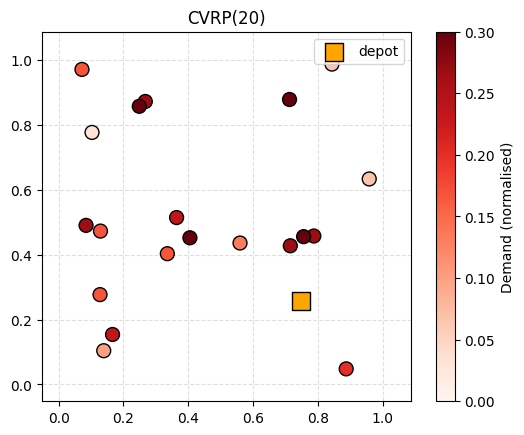

In [10]:
cvrp_config = CVRPConfig.for_n(20)
cvrp_sampler = TensorDictCVRPSampler(cvrp_config)
td = cvrp_sampler(2)
print(td)
print(td[0])

cvrp_instance = CVRPInstance.from_td(td[0])
cvrp_instance.visualize()
plt.show()

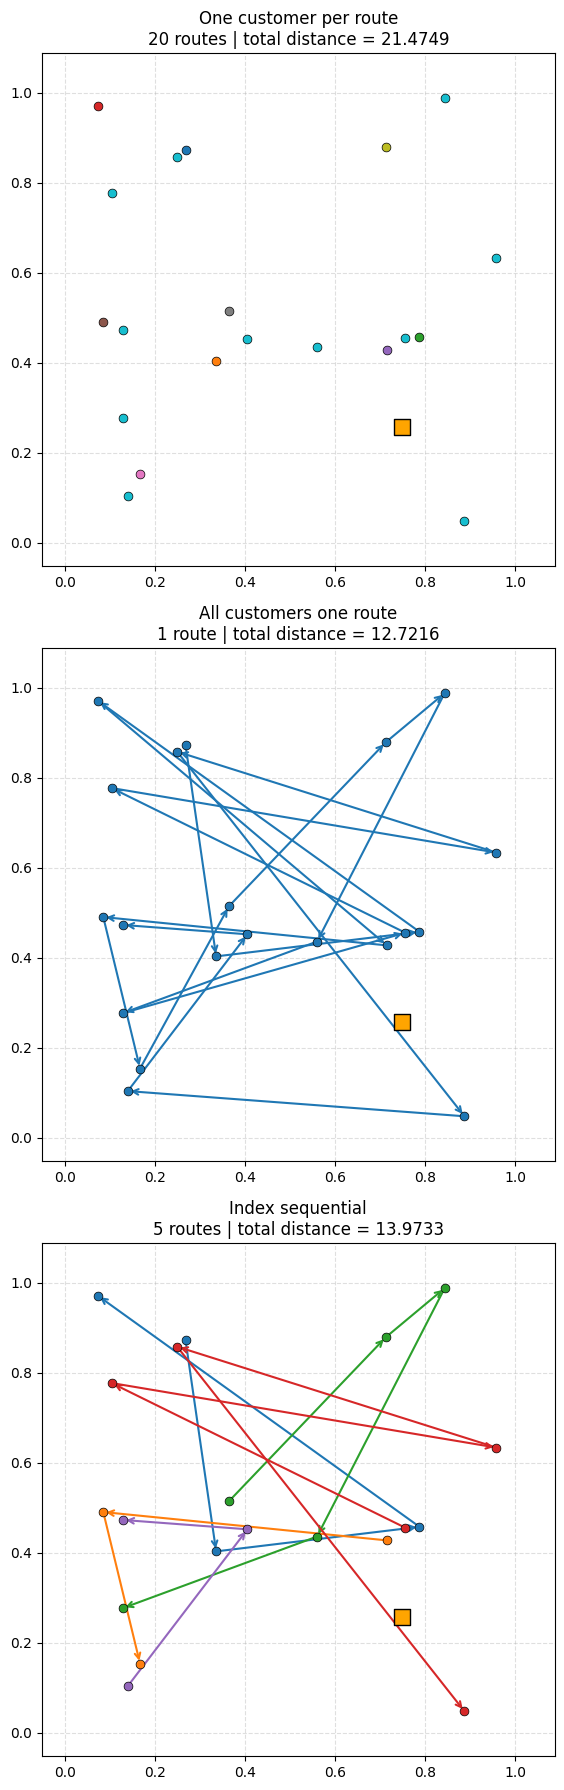

In [29]:
from core.problems.cvrp.solve import (
    all_customers_one_route,
    index_sequential,
    one_customer_per_route,
)

fig, axes = plt.subplots(3, 1, figsize=(6, 18))

strategies = [
    (one_customer_per_route, "One customer per route"),
    (all_customers_one_route, "All customers one route"),
    (index_sequential, "Index sequential"),
]

for ax, (strategy, title) in zip(axes, strategies):
    solution: CVRPSolution = strategy(cvrp_instance)
    solution.visualize(
        ax=ax, with_problem_size=False, depot_in_legend=False, with_route_labels=False
    )
    ax.set_title(f"{title}\n{ax.get_title()}")

plt.tight_layout()
plt.show()

## Orienteering Problem

**1. Constant**

TensorDict(
    fields={
        depot: Tensor(shape=torch.Size([1, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        locs: Tensor(shape=torch.Size([1, 20, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        max_length: Tensor(shape=torch.Size([1]), device=cpu, dtype=torch.float32, is_shared=False),
        prize: Tensor(shape=torch.Size([1, 20]), device=cpu, dtype=torch.float32, is_shared=False)},
    batch_size=torch.Size([1]),
    device=None,
    is_shared=False)
TensorDict(
    fields={
        depot: Tensor(shape=torch.Size([2]), device=cpu, dtype=torch.float32, is_shared=False),
        locs: Tensor(shape=torch.Size([20, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        max_length: Tensor(shape=torch.Size([]), device=cpu, dtype=torch.float32, is_shared=False),
        prize: Tensor(shape=torch.Size([20]), device=cpu, dtype=torch.float32, is_shared=False)},
    batch_size=torch.Size([]),
    device=None,
    is_shared=False)


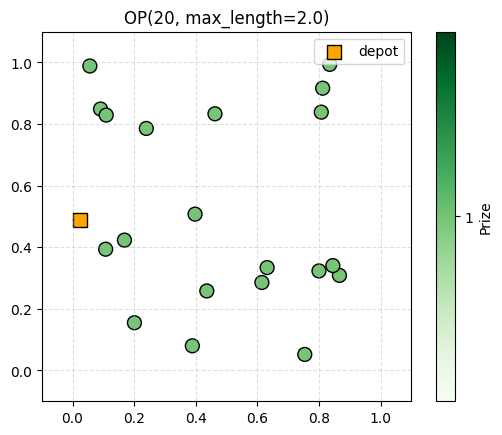

In [10]:
op_config = OPConfig(num_nodes=20, prize_type="const")
op_generator = get_op_generator(op_config)
op_generator.device = "cpu"
td = op_generator([1])
print(td)

print(td[0])

min_loc = op_generator.min_loc
max_loc = op_generator.max_loc

visualize_op_instance(td[0], min_loc, max_loc, prize_type="const")
plt.show()

**2. Uniform**

TensorDict(
    fields={
        depot: Tensor(shape=torch.Size([1, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        locs: Tensor(shape=torch.Size([1, 20, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        max_length: Tensor(shape=torch.Size([1]), device=cpu, dtype=torch.float32, is_shared=False),
        prize: Tensor(shape=torch.Size([1, 20]), device=cpu, dtype=torch.float32, is_shared=False)},
    batch_size=torch.Size([1]),
    device=None,
    is_shared=False)


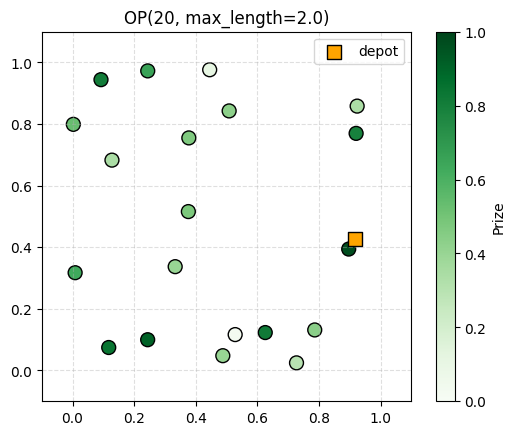

In [11]:
op_config = OPConfig(num_nodes=20, prize_type="unif")
op_generator = get_op_generator(op_config)
op_generator.device = "cpu"
td = op_generator([1])
print(td)

min_loc = op_generator.min_loc
max_loc = op_generator.max_loc

locations = td["locs"][0].cpu().numpy()
depot = td["depot"][0].cpu().numpy()
prizes = td["prize"][0].cpu().numpy()
max_length = td["max_length"][0].item()

visualize_op_instance(td[0], min_loc, max_loc, prize_type="unif")
plt.show()

**3. Distance**

TensorDict(
    fields={
        depot: Tensor(shape=torch.Size([1, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        locs: Tensor(shape=torch.Size([1, 20, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        max_length: Tensor(shape=torch.Size([1]), device=cpu, dtype=torch.float32, is_shared=False),
        prize: Tensor(shape=torch.Size([1, 20]), device=cpu, dtype=torch.float32, is_shared=False)},
    batch_size=torch.Size([1]),
    device=None,
    is_shared=False)


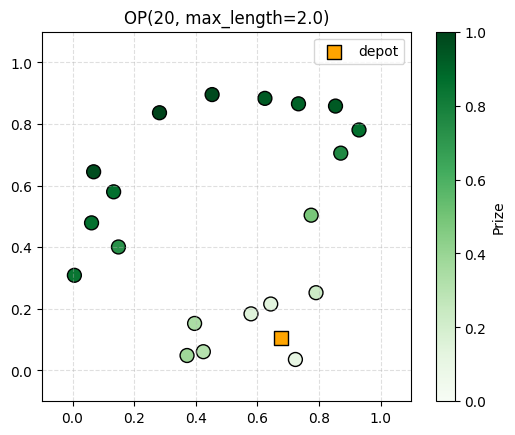

In [12]:
op_config = OPConfig(num_nodes=20, prize_type="dist")
op_generator = get_op_generator(op_config)
td = op_generator([1])
print(td)

min_loc = op_generator.min_loc
max_loc = op_generator.max_loc

visualize_op_instance(td[0], min_loc, max_loc, prize_type="dist")
plt.show()